# CBMViz Additional Features

In [1]:
import os
import cbmviz




No module named cplex



CPLEX not available

*****
Using GLPK
*****


WX GUI tools not available.
No module named wx
GUI module not available
No Matplotlib available

CBMPy environment
******************
Revision: r515


***********************************************************************
* Welcome to CBMPy (0.7.7) - PySCeS Constraint Based Modelling        *
*                http://cbmpy.sourceforge.net                         *
* Copyright(C) Brett G. Olivier 2014 - 2016                           *
* Dept. of Systems Bioinformatics                                     *
* Vrije Universiteit Amsterdam, Amsterdam, The Netherlands            *
* CBMPy is developed as part of the BeBasic MetaToolKit Project       *
* Distributed under the GNU GPL v 3.0 licence, see                    *
* LICENCE (supplied with this release) for details                    *
***********************************************************************

######################################################

CBMViz offers a range of additional features besides its core layouting pipeline such as extra coloring modes or alternative layouting options. In order to enable these options, corresponding control variables need to be changed. These variables can be found in a dictionary which makes it possible to change them by using the **update** method.

## The control dictionary *cfg_default* 

In [2]:
# get configuration dictionary with default values
global_ops = cbmviz.cfg_default

The configuration dictionary *cfg_default* contains the following keys which control different CBMViz features:


    - AUTO_ALIAS [default: False] 
    enable automatic layouting (if no groups are defined in input SBML file)
    - AUTO_ALIAS_OPTIONS [default: {'reac_split': 4, 'spec_split': 6}] 
    options for automatic layouting: threshold values at which a reaction (reac_split) and a species (spec_split) 
    is considered to be 'highly connected' which means the corresponding reaction/species node will be cloned 
    as often as necessary instead of having one node with too many connected edges.

    - LAYOUT_PATHWAYS [default: True] 
    enable layouting based on pathways which are defined in groups
    - PATHWAY_LISTS [default: True] 
    create internal data structures for each pathway (needs to be true if pathway layouting was enabled)
    - SMALL_THRSH [default: 30] 
    defines a threshold at which species are defined as "small" (which in CBMViz is an estimation to identify cofactors)
        
    - LABEL_TYPE [default: 'id']
    define which node property is used for labels (can be 'name' or 'id')
    - LABEL_FONT_SIZE [default: 18]
    set the font size of all node labels
    
    - ADD_COFACTORS [default: False]
    add species which have been identified as cofactors to a selected group (depending on the SMALL_THRSH)
    - TRANSPORT_RADIAL [default: False]
    layout the transport reactions of the model radially around the main body of the model map (see: examples)
    
    - METABOLITE_NODE_SIZE [default: 2.5]
    - REACTION_NODE_SIZE [default: 1]
    - COFACTOR_NODE_SIZE [default: 1.5]
    define the size of metabolite, cofactor and reaction nodes (relative units)
    
    - SELECTED_PATHWAYS [default: ['objective reaction', 'Transport']]
    select certain groups by name to create a separate map (saved as 'output_selected' inside the output directory) 
    - GRID_OUTPUT [default: ['Glycolysis', 'TCA cycle', 'Respiratory chain', 'Aminosugar Metabolism']]
    select certain groups by name to create a separate map (saved as 'output_grid' inside the output directory) 
    
    - EXPORT_TLP [default: True]
    - EXPORT_GML [default: True]
    - EXPORT_SVG [default: True]
    - EXPORT_JSON [default: True] 
    - EXPORT_SBML [default: True] 
    - EXPORT_SBGN [default: True]
    control different types of graph exports

    - COLOR_FBA [default: True]
    - COLOR_FBA_COLORBLIND [default: False]
    color reaction edges based on FBA results (flux values)
    - COLOR_PATHWAYS [default: False]
    color reaction edges based on pathway membership
    - COLOR_GAPS [default: False]
    for two models where one is a smaller submodel of the other: color reaction edges in a binary way based on existence
    in the bigger model (black = reaction exists in both, red = reaction exists only in the bigger model)    

## Examples

In [3]:
# increase node sizes to better see them in ipython notebook embedding of resulting SVG files
global_ops.update({"METABOLITE_NODE_SIZE": 15})
global_ops.update({"COFACTOR_NODE_SIZE": 12.5})
global_ops.update({"REACTION_NODE_SIZE": 10})

### Change Layout 

1.) Demonstration of different CBMViz features using the TCA cycle map of the H.pylori model iIT341.

FBC version: 2
M.getNumReactions: 554
M.getNumSpecies: 485
FBC.getNumObjectives: 1
FBC.getNumParameters: 15
FBC.getNumGeneProducts: 339
Zero dimension compartment detected: c
Zero dimension compartment detected: e
INFO: Active objective: obj
'ascii' codec can't decode byte 0xc2 in position 83: ordinal not in range(128)
Adding objective: obj
Groups support: <GroupsModelPlugin>
Group.getNumGroups: 70

SBML3 load time: 3.093


Replaced 553 "999999" bounds with "inf"

Replaced 172 "-999999" bounds with "-inf"

Replaced 0 "1000" bounds with "inf"

Replaced 0 "-1000" bounds with "-inf"
 

gplk_constructLPfromFBA time: 0.577000141144


glpk_analyzeModel FBA --> LP time: 0.0


analyzeModel objective value: 0.692812693473


 Pathway dictionary generated. 


 Initial Tulip graph saved as: iIT341_initial.tlp. 


 Applied flux coloring to all graphs. 


 Applied reaction and metabolite node specific coloring to all graphs. 


 Visualization of aligned pathways saved at: C:\Users\Nicolas\surfdrive\

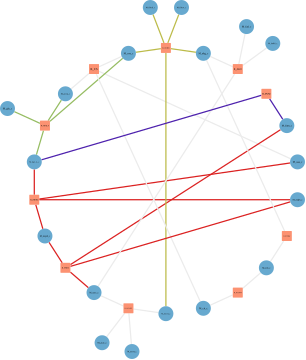

In [4]:
# create a map of the TCA cycle with default configs
sbml = os.path.join("TestModels", "iIT341.xml")
graph, graph_props = cbmviz.createInitialGraph("iIT341")
cmod, fba_results, graph_registry, cDir, output_path = cbmviz.layoutModel(global_ops, sbml, graph, graph_props)
cbmviz.colorGraphs(global_ops, fba_results, graph_registry, output_path, "iIT341")
cbmviz.exportGraph(output_path, graph_registry, global_ops, cDir, "iIT341")
from IPython.display import SVG
SVG(filename='iIT341_Output\\TCAcycle.svg')

FBC version: 2
M.getNumReactions: 554
M.getNumSpecies: 485
FBC.getNumObjectives: 1
FBC.getNumParameters: 15
FBC.getNumGeneProducts: 339
Zero dimension compartment detected: c
Zero dimension compartment detected: e
INFO: Active objective: obj
'ascii' codec can't decode byte 0xc2 in position 83: ordinal not in range(128)
Adding objective: obj
Groups support: <GroupsModelPlugin>
Group.getNumGroups: 70

SBML3 load time: 2.529


Replaced 553 "999999" bounds with "inf"

Replaced 172 "-999999" bounds with "-inf"

Replaced 0 "1000" bounds with "inf"

Replaced 0 "-1000" bounds with "-inf"
 

gplk_constructLPfromFBA time: 0.638999938965


glpk_analyzeModel FBA --> LP time: 0.0


analyzeModel objective value: 0.692812693473


 Pathway dictionary generated. 


 Initial Tulip graph saved as: iIT341_initial.tlp. 

TCA cycle subgraph incomplete! 


 Applied flux coloring to all graphs. 


 Applied reaction and metabolite node specific coloring to all graphs. 


 Visualization of aligned pathways save

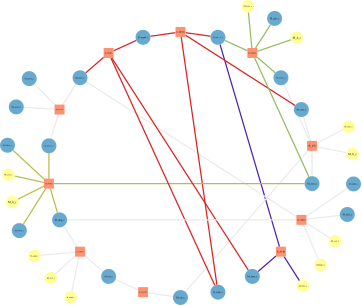

In [5]:
# show cofactors (yellow nodes in output graph)
global_ops.update({"ADD_COFACTORS": ["TCA cycle"]})
# change threshold level to fit model and capture all cofactors
global_ops.update({"SMALL_TRHSH": 20})

cmod, fba_results, graph_registry, cDir, output_path = cbmviz.layoutModel(global_ops, sbml, graph, graph_props)
cbmviz.colorGraphs(global_ops, fba_results, graph_registry, output_path, "iIT341")
cbmviz.exportGraph(output_path, graph_registry, global_ops, cDir, "iIT341")

from IPython.display import SVG
SVG(filename='iIT341_Output\\TCAcycle.svg')

2.) Layout the transport reactions of iIT341 in a circle.

FBC version: 2
M.getNumReactions: 554
M.getNumSpecies: 485
FBC.getNumObjectives: 1
FBC.getNumParameters: 15
FBC.getNumGeneProducts: 339
Zero dimension compartment detected: c
Zero dimension compartment detected: e
INFO: Active objective: obj
'ascii' codec can't decode byte 0xc2 in position 83: ordinal not in range(128)
Adding objective: obj
Groups support: <GroupsModelPlugin>
Group.getNumGroups: 70

SBML3 load time: 3.393


Replaced 553 "999999" bounds with "inf"

Replaced 172 "-999999" bounds with "-inf"

Replaced 0 "1000" bounds with "inf"

Replaced 0 "-1000" bounds with "-inf"
 

gplk_constructLPfromFBA time: 0.539000034332


glpk_analyzeModel FBA --> LP time: 0.0


analyzeModel objective value: 0.692812693473


 Pathway dictionary generated. 


 Initial Tulip graph saved as: iIT341_initial.tlp. 

TCA cycle subgraph incomplete! 


 Applied flux coloring to all graphs. 


 Applied reaction and metabolite node specific coloring to all graphs. 


 Visualization of aligned pathways save

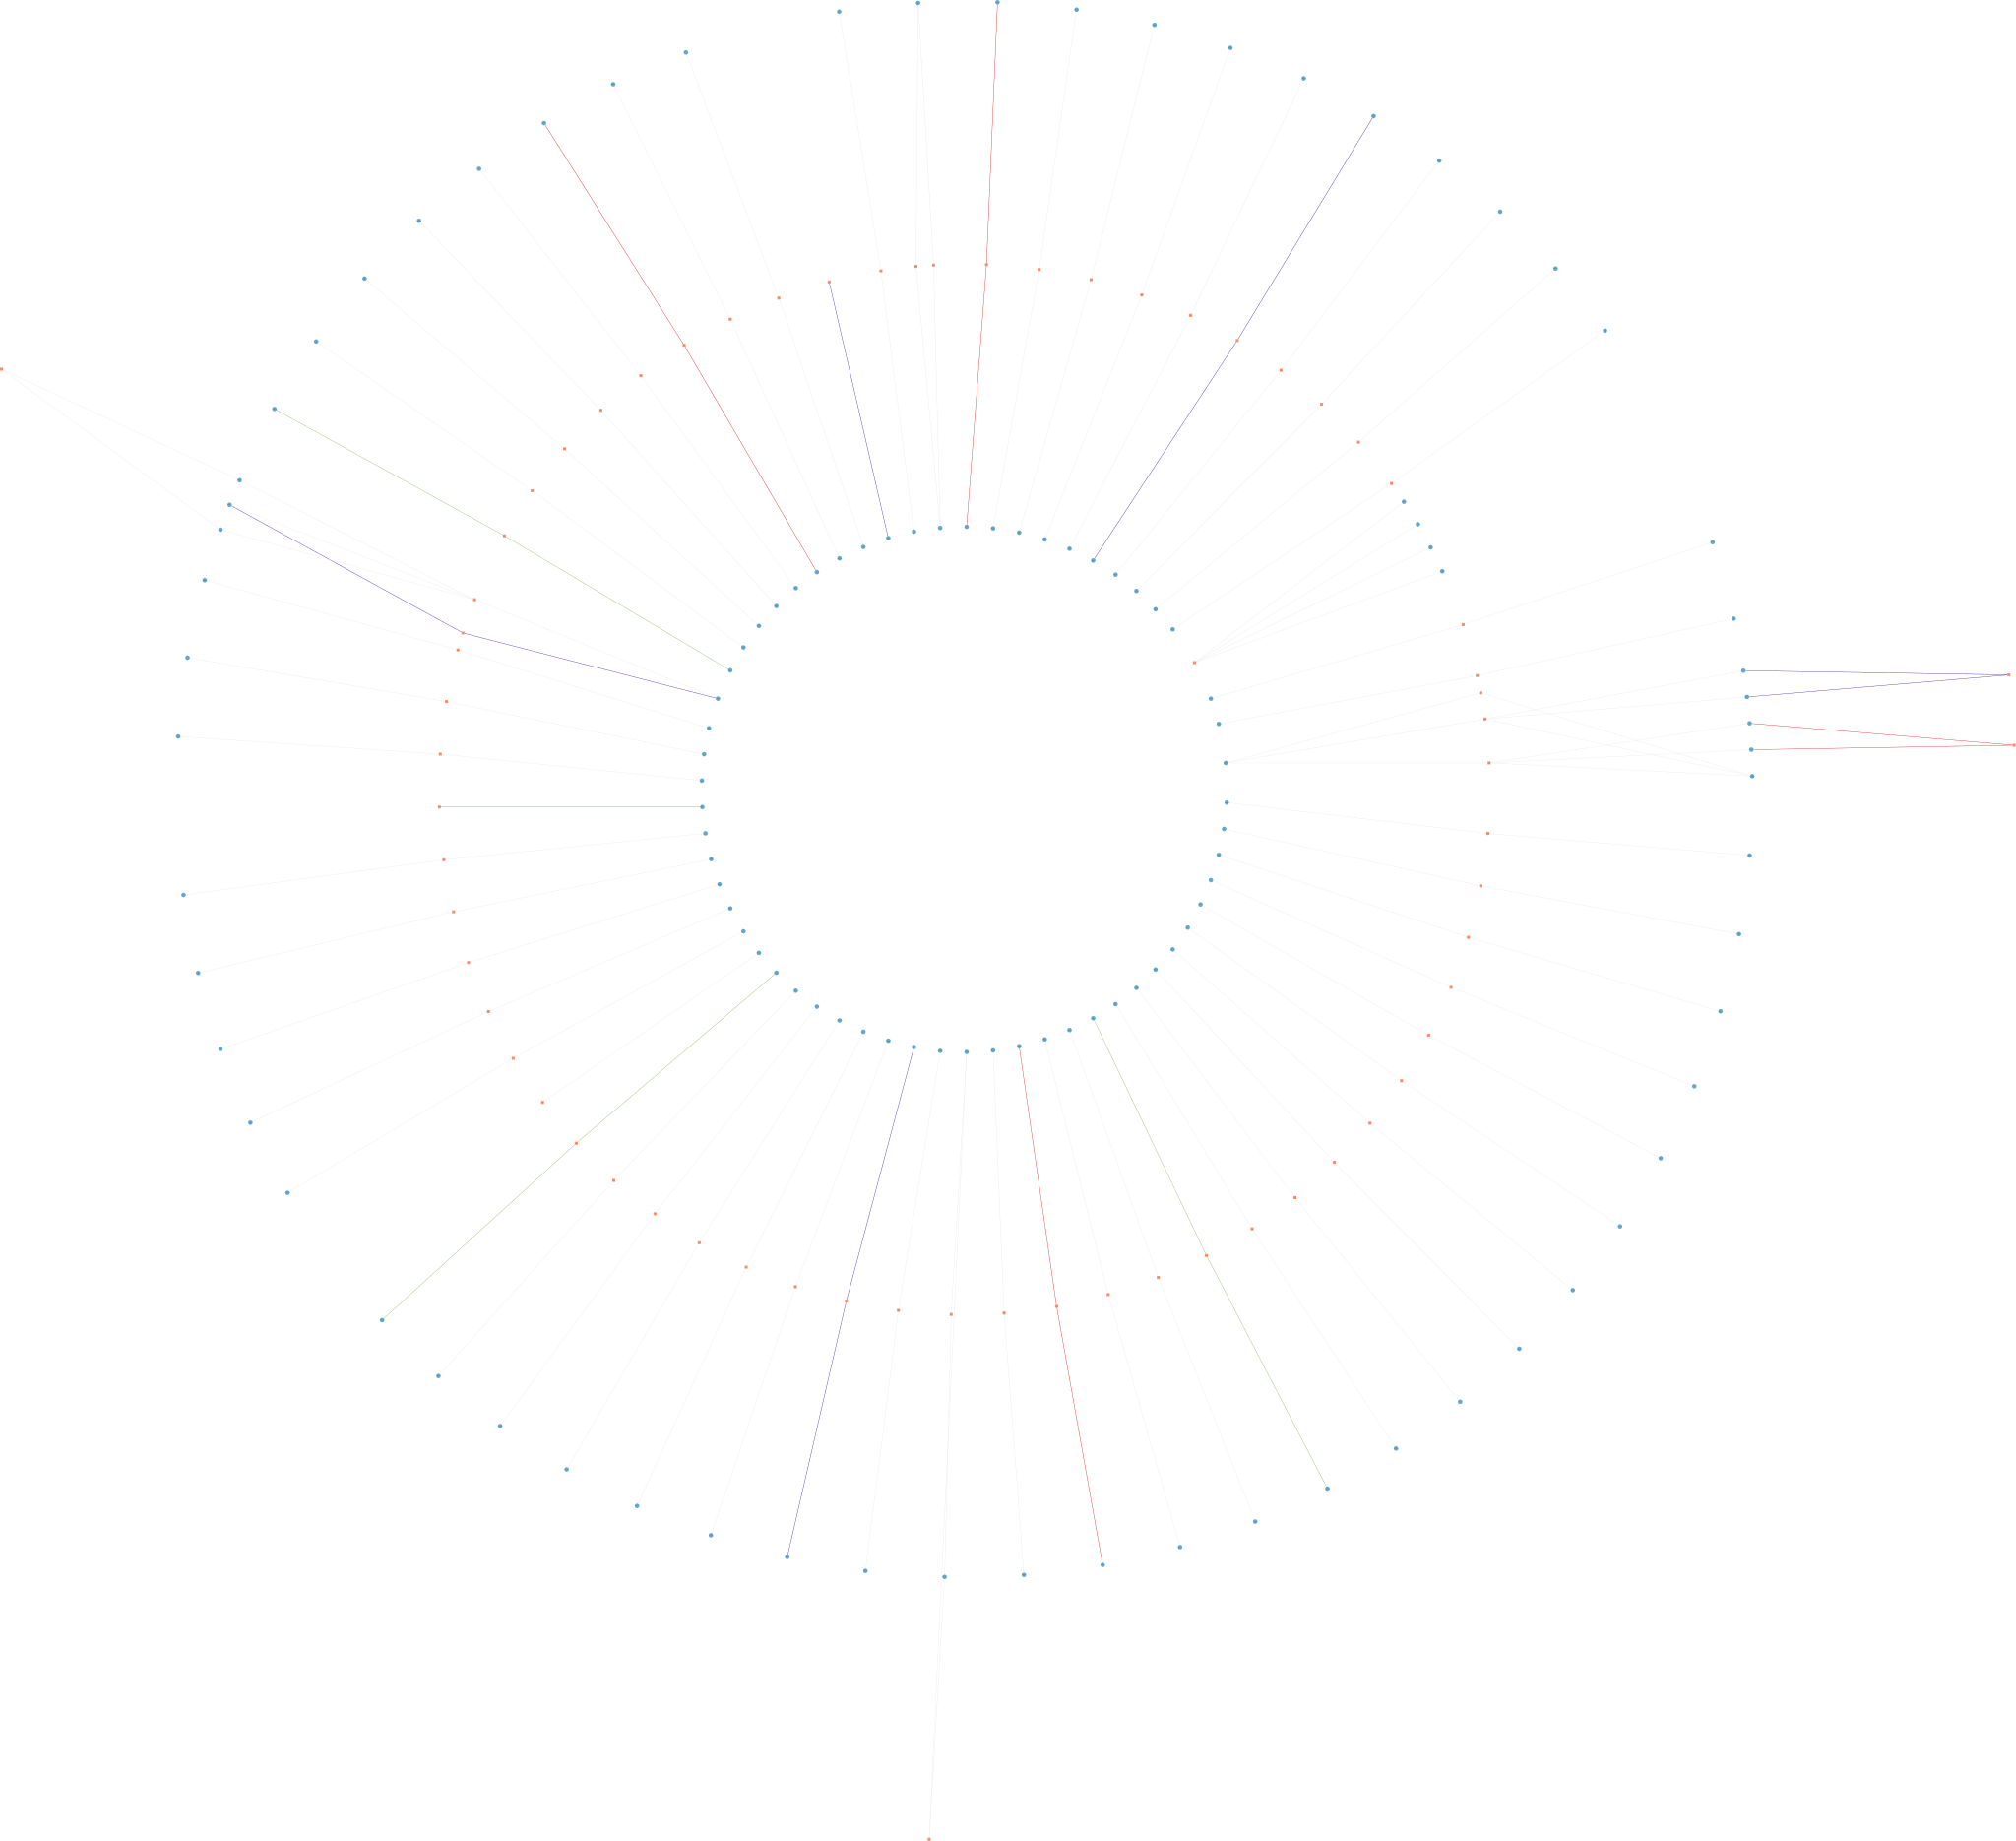

In [6]:
# turn on radial layout for transport reactions
global_ops.update({"TRANSPORT_RADIAL": True})

graph, graph_props = cbmviz.createInitialGraph("iIT341")
cmod, fba_results, graph_registry, cDir, output_path = cbmviz.layoutModel(global_ops, sbml, graph, graph_props)
cbmviz.colorGraphs(global_ops, fba_results, graph_registry, output_path, "iIT341")
cbmviz.exportGraph(output_path, graph_registry, global_ops, cDir, "iIT341")

from IPython.display import SVG
SVG(filename='iIT341_Output\\Transport.svg')

### Change Rendering 

Changing options by updating the dictionary is necessary if  the enabled features affect the layout meaning that **layoutModel** needs to be run again. 

However, some options (such as changing the label type) do not affect the layout but are only cosmetic properties of the rendering. As such, running the layouting function all over again is not necessary. 

Instead, the existing layout can be loaded from a file with the function **loadGraphObjFromFile** and the retrieved graph object can then be modified directly by calling the appropriate CBMViz functions (which otherwise reside inside **layoutModel** and are controlled by *global_ops*).

After wrapping the modified graph object into a graph dictionary with the function **createGraphDictFromGraphObj**, the coloring and export functions can be called.

1.) Change the label type from 'id' to 'name' for all nodes.


 Applied flux coloring to all graphs. 


 Applied reaction and metabolite node specific coloring to all graphs. 


 Whole network visualization saved at: C:\Users\Nicolas\surfdrive\LabR1_Teusink_Amsterdam\Project\Documentation\iIT341_Output\output_whole.tlp
Graph exported as: output_whole.gml
Graph exported as: TCAcycle_TCA cycle.gml
Graph exported as: output_whole.svg
Graph exported as: TCAcycle_TCA cycle.svg
Graph exported as: output_whole.json
Graph exported as: TCAcycle_TCA cycle.json


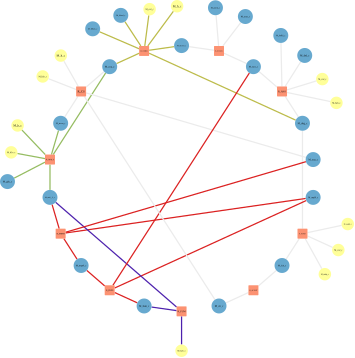

In [7]:
# load a graph object from an already existing layout (e.g. a JSON file)
existing_layout = os.path.join('iIT341_Output', 'TCAcycle.json')
input_graph = cbmviz.loadGraphObjFromFile(existing_layout)

# change label types from ids to names
cbmviz.labelGraphNodes(input_graph, 'name')

# generate a dictionary from the graph object
input_graph_dict = cbmviz.createGraphDictFromGraphObj(input_graph)

# run coloring and exporting functions
cbmviz.colorGraphs(global_ops, fba_results, input_graph_dict, output_path, "iIT341")
cbmviz.exportGraph(output_path, input_graph_dict, global_ops, cDir, "iIT341")
from IPython.display import SVG
SVG(filename='iIT341_Output\\TCAcycle.svg')

Some rendering options require additional information from the SBML model file. In such cases the function **createCBMPYModel** can be used to generate an abstract model object *cmod* from an input SBML file. It also returns the stoichiometric matrix as numpy array (*stM*) and the id of the objective reaction (*obj_re_id*). 

In [8]:
# read an SBML model file and create a CBMPY model object
sbml = os.path.join(cDir, "TestModels", "iIT341.xml")
cmod, stM, obj_re_id  = cbmviz.createCBMPYModel(sbml)

FBC version: 2
M.getNumReactions: 554
M.getNumSpecies: 485
FBC.getNumObjectives: 1
FBC.getNumParameters: 15
FBC.getNumGeneProducts: 339
Zero dimension compartment detected: c
Zero dimension compartment detected: e
INFO: Active objective: obj
'ascii' codec can't decode byte 0xc2 in position 83: ordinal not in range(128)
Adding objective: obj
Groups support: <GroupsModelPlugin>
Group.getNumGroups: 70

SBML3 load time: 2.913


Replaced 553 "999999" bounds with "inf"

Replaced 172 "-999999" bounds with "-inf"

Replaced 0 "1000" bounds with "inf"

Replaced 0 "-1000" bounds with "-inf"
 


2.) Color edges based on group membership.

Coloring edges based on group membership (pathway coloring) instead of based on flux values (FBA coloring) requires the SBML group information which is stored in the CBMPY model object *cmod*. 
The function **automPathDict** can create a dictionary which contains lists of group element ids which then can be transformed by another function (**createPathColoringDict**). The resulting, new dictionary is now in a format (keys: reaction ids, values: float values) that is recognized by the coloring function.

In [9]:
# create the input dictionary for the coloring function
path_dict, small_sps_dict = cbmviz.automPathDict(cmod, global_ops)
coloring_dict = cbmviz.createPathColoringDict(path_dict)


 Pathway dictionary generated. 




 Applied pathway coloring to all graphs. 


 Applied reaction and metabolite node specific coloring to all graphs. 


 Whole network visualization saved at: C:\Users\Nicolas\surfdrive\LabR1_Teusink_Amsterdam\Project\Documentation\iIT341_Output\output_whole.tlp
Graph exported as: output_whole.gml
Graph exported as: TCAcycle_TCA cycle.gml
Graph exported as: output_whole.svg
Graph exported as: TCAcycle_TCA cycle.svg
Graph exported as: output_whole.json
Graph exported as: TCAcycle_TCA cycle.json


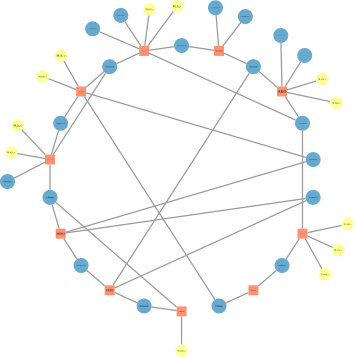

In [12]:
# color edges based on group membership instead of flux values
global_ops.update({"COLOR_FBA": False})
global_ops.update({"COLOR_PATHWAYS": True})

# run coloring and exporting functions
cbmviz.colorGraphs(global_ops, coloring_dict, input_graph_dict, output_path, "iIT341")
cbmviz.exportGraph(output_path, input_graph_dict, global_ops, cDir, "iIT341")
from IPython.display import SVG
SVG(filename='iIT341_Output\\TCAcycle_TCAcycle.svg')